# Exercices 7

[Télécharger l'exercice](../07_exercice.zip)

# Exercise : Evolution du permafrost au Cervin

Pour un premier exercice en deux dimensions, nous allons modéliser l'évolution de la température au sein du Cervin (coupe nord-sud) sous l'effet du réchauffement climatique. L'augmentation des températures en haute montagne est particulièrement problématique pour la stabilité des pentes et falaises dont la cohésion dépend de la présence de glace. Dans cet exercice, nous allons augmenter la température des flancs du Cervin (auparavent en équilibre thermique) et observer la migration de la limite du permafrost (et de fait l'étendue des pentes destabilisées). 
 
![](../illu_mod_num_s.png)
 
## 1. Modèle élémentaire

Avant de s'attaquer au Cervin, nous allons faire un modèle élémentaire dans un simple carré.  

Le point clé de ce problème est de résoudre la diffusion dans un domaine en deux dimensions (2D), rectangulaire (Figure ci-dessous). L'évolution du champ de température $T$ qui se diffuse en deux dimensions ($x$ et $y$) est décrit par deux flux ($x$ et $y$) qui se combinent dans le taux de changement: 

$$\frac{\partial T}{\partial t} = -\left(\frac{\partial q_x}{\partial x} +\frac{\partial q_y}{\partial y}\right)\:$$

et

$$q_x = - D \frac{\partial T}{\partial x} \: ; \: \: q_y = - D \frac{\partial T}{\partial y}.$$

Nous commençons par modéliser l'évolution du champs de température dans un rectangle dont les paramètres (y compris les conditions initiales et de bords) sont donnés dans la Table. La matrice des températures peut être affichée avec `ax.imshow` comme dans la figure suivante.
 
![](./fig/initial_rectangle.png)

*L'équilibrage de la diffusion de température en deux dimensions sur un rectangle simple, ici avec des valeurs de conditions limites de 5°C et 15°C respectivement."

### Paramètres

| **Paramètres**                       | **Valeurs**                          |
|--------------------------------------|--------------------------------------|
| Longueur x                           | 3000 m                               |
| Longueur y                           | 3000 m                               |
| Température initiale                 | 10°C                                 |
| Diffusivité                          | 3500 m²/yr                           |
| Nombre de cellules nx                | 60                                   |
| Nombre de cellules ny                | 70                                   |
|                                      |                                      |
| **modèle élémentaire:**              |                                      |
| Température bord gauche              | 5°C                                  |
| Température bord droite              | 15°C                                 |
| Température bord haut                | 5°C                                  |
| Température bord bas                 | 15°C                                 |
| Temps total                          | 500 yr                               | 


### ✅ **À vous de faire !** 

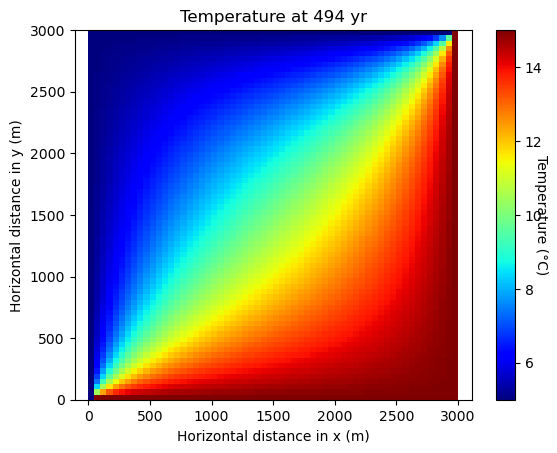

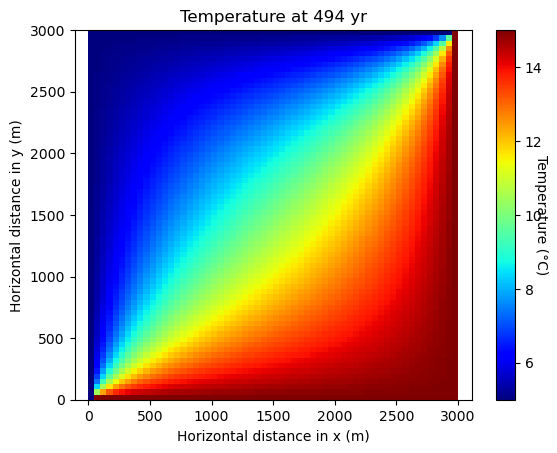

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# PARAMèTRES PHYSIQUES
D = 3500            # diffusivité en m2/an
Lx = 3000           # longueur du modèle en m
Ly = 3000           # hauteur du modèle en m
T_ini = 10          # température initiale en °C
Tg = 5              # température bord gauche
Td = 15             # température bord droit
Th = 5              # température bord haut
Tb = 15             # température bord bas
ttot = 500          # temps total en années

# PARAMèTRES NUMéRIQUES
nx = 60                             # nombre de cellules (x)
ny = 70                             # nombre de cellules (y)
dx = Lx / (nx - 1)                  # pas d'espace en x
dy = Ly / (ny - 1)                  # pas d'espace en y
x = np.linspace(0, Lx, nx)          # vecteur coordonnées en x
y = np.linspace(0, Ly, ny)          # vecteur coordonnées en y
dt = 0.5*((min(dx, dy))**2)/(4.1*D) # pas de temps
nt = int(ttot/dt)                   # nombre de pas de temps
nout = 100

# INITIALISATION  
T = np.ones((ny,nx)) * T_ini        # initialisation d'une temperature constante
time = 0                            # initialisation du temps

# CRéATION DU PLOT 
# definit fig et ax
fig, ax = plt.subplots() 
# affiche la temperature initiale
s = ax.imshow(T, extent=[0, Lx, 0, Ly], origin='lower', cmap='jet') 
# definit la "colorbar" pour qu'elle soit fixe lors de l'affichage interactif
cbar = plt.colorbar(s) 
# Affiche un titre a la colorbar
cbar.set_label("Temperature (°C)", rotation=270) 
# fixe les valeurs limite de la temperature dans la colorbar
s.set_clim(5,15)

# BOUCLE TEMPORELLE
for it in range(nt):
    # conditions de bord
    T[0, :]  = Tb   # 1ere ligne
    T[-1, :] = Th   # derniere ligne
    T[:, 0]  = Tg   # 1ere colonne
    T[:, -1] = Td   # derniere colonne

    time += dt
    qx = -D * (T[:,1:] - T[:,:-1]) / dx
    qy = -D * (T[1:,:] - T[:-1,:]) / dy
    dqxdx = (qx[:,1:] - qx[:,:-1]) / dx
    dqydy = (qy[1:,:] - qy[:-1,:]) / dy
    T[1:-1, 1:-1] += -( dqxdx[1:-1,:] + dqydy[:,1:-1] ) * dt  # mise à jour
    
    
     
    if it % nout == 0:
        clear_output(wait=True)  
        ax.cla() 
        ax.imshow(T, extent=[0, Lx, 0, Ly], origin='lower', cmap='jet')
        plt.gca().set_aspect("auto")
        plt.axis('equal')
        ax.set_title(f'Temperature at ' + str(int(time)) + ' yr')
        ax.set_xlabel('Horizontal distance in x (m)')
        ax.set_ylabel('Horizontal distance in y (m)')
        display(fig)


## 2. Modèle réaliste du Cervin

Afin de modéliser le Cervin simplement, nous réduirons sa géométrie à un carré, qu'il faudra imaginer tourné d'un angle de 45°. Nous reprendrons le code du modèle élémentaire.

Nous créons deux vecteurs de conditions de bord qui représentent les faces nord et sud de la montagne. La température de la face nord va de 10°C au pied de la montagne à -15°C au sommet, et de 15 à -5°C en face sud. 

Le modèle tournera d'abord pendant 500 ans pour approcher un équilibre thermique. Puis, le réchauffement des faces sud et nord peut commencer (en modifiant les conditions limites nord et sud uniformément). Une fois que l'équilibrage thermique fonctionne bien, l'affichage des figures peut être limité à la dernière phase de réchauffement (100 ans au total). 

Bien que ce modèle soit trés simplifié, il nous permet de constater une dynamique existante dans le massif Alpin. En observant le déplacement de la limite du zéro degré Celsius, nous pouvons nous interroger sur le risque lié à la fonte du pergélisol en milieu alpin, avec les conséquence sur le paysage et la société. 

Les valeurs de bord et de réchauffement de la Table ci-dessous ne sont que des suggestions, nous pouvons explorer une myriade de scénarios.  
 
| **Paramètres**                       | **Valeurs**                          |
|--------------------------------------|--------------------------------------|
| **modèle réaliste:**                 |                                      |
| Température face nord                | gradient de 10 à -15°C              |
| Température face sud                 | gradient de 15 à -5°C                |
| Température bords restants           | 10°C                                 |
| Temps total                          | 600 yr                               |
| Début du réchauffement               | 500 yr                               |
| Réchauffement au nord                | +0.04°C/yr                          |
| Réchauffement au sud                 | +0.08°C/yr                          |

![](./fig/matterhorn.png)

*But de l'exercice: Modéliser le géotherme au travers du Matterhorn (sérieusement idéalisé) après 100 ans de réchauffement. Il faut tourner la tête de 45° pour s'imaginer le Matterhorn pointant au ciel.*

### ✅ **À vous de faire !** 

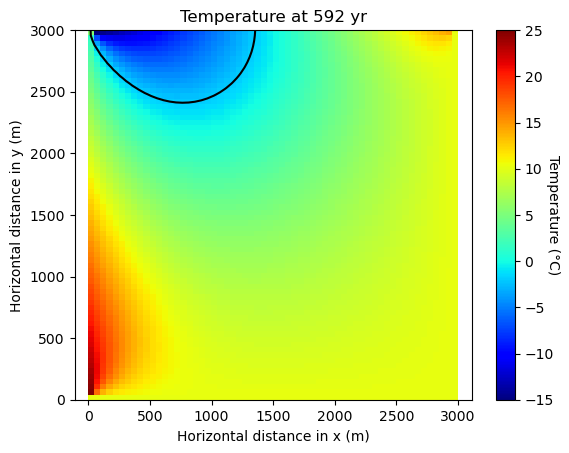

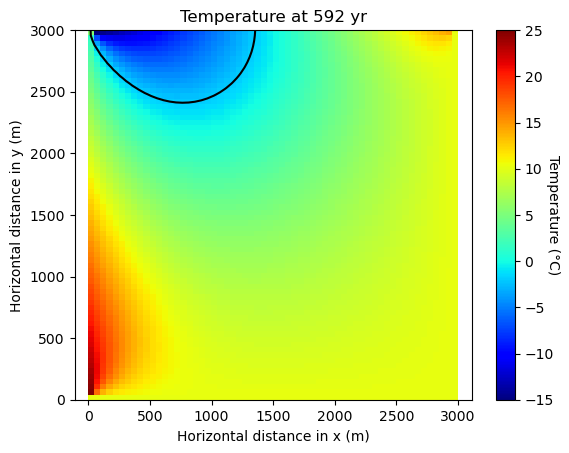

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# PARAMèTRES PHYSIQUES
D = 3500            # diffusivité en m2/an
Lx = 3000           # longueur du modèle en m
Ly = 3000           # hauteur du modèle en m
T_ini = 10          # température initiale en °C
Tb = 10             # température face est et ouest
ttot = 600          # temps total en années
trech = 500         # temps début réchauffement
rn = 0.04           # récahuffement face nord en °C/an
rs = 0.08           # récahuffement face sud en °C/an

# PARAMèTRES NUMéRIQUES
nx = 60                         # nombre de cellules (x)
ny = 70                         # nombre de cellules (y)
dx = Lx / (nx - 1)              # pas d'espace en x
dy = Ly / (ny - 1)              # pas d'espace en y
x = np.linspace(0, Lx, nx)      # vecteur coordonnées en x
y = np.linspace(0, Ly, ny)      # vecteur coordonnées en y
dt = 0.5*((min(dx, dy))**2)/(4.1*D) # pas de temps
nt = int(ttot/dt)               # nombre de pas de temps
nout = 200                      # affichage toutes les nout itérations

Tn = np.linspace(-15, 10, nx)   # température face nord
Ts = np.linspace(15, -5, ny)    # température face sud

# INITIALISATION  
T = np.ones((ny,nx)) * T_ini # initialisation d'une temperature constante
time = 0 

# CRéATION DU PLOT 
# definit fig et ax
fig, ax = plt.subplots() 
# affiche la temperature initiale
s = ax.imshow(T, extent=[Lx, 0, 0, Ly], origin='lower', cmap='jet') 
# definit la "colorbar" pour qu'elle soit fixe lors de l'affichage interactif
cbar = plt.colorbar(s) 
# Affiche un titre a la colorbar
cbar.set_label("Temperature (°C)", rotation=270) 
# fixe les valeurs limite de la temperature dans la colorbar
s.set_clim(-15,25)

# Create a meshgrid for x and y
X, Y = np.meshgrid(x, y) # ajouté par la suite

# BOUCLE TEMPORELLE
for it in range(nt):
    time += dt
    # conditions de bord avant réchauffement (avant 500 ans)
    if time < trech: 
        T[0, :]  = Tb   # 1ere ligne
        T[-1, :] = Tn   # derniere ligne
        T[:, 0]  = Ts   # 1ere colonne
        T[:, -1] = Tb   # derniere colonne
    # conditions de bord pendant récahuffement
    elif time >= trech: 
        T[0, :] = Tb        # 1ere ligne
        T[-1, :] += rn*dt   # derniere ligne
        T[:, 0]  += rs*dt   # 1ere colonne
        T[:, -1] = Tb       # derniere colonne

    qx = -D * (T[:,1:] - T[:,:-1]) / dx                         # flux dans la dimention x
    qy = -D * (T[1:,:] - T[:-1,:]) / dy                         # flux dans la dimention y
    dqxdx = (qx[:,1:] - qx[:,:-1]) / dx                         # dérivée du flux (x) en fonction de la position (dx)
    dqydy = (qy[1:,:] - qy[:-1,:]) / dy                         # dérivée du flux (y) en fonction de la position (dy)
    T[1:-1, 1:-1] += -( dqxdx[1:-1,:] + dqydy[:,1:-1] ) * dt    # mise à jour
     
    if it % nout == 0:
        clear_output(wait=True)  
        ax.cla() 
        ax.imshow(T, extent=[0, Lx, 0, Ly], origin='lower', cmap='jet')
        plt.gca().set_aspect("auto")
        plt.axis('equal')
        ax.contour(X, Y, T, levels=[0], colors='k') # ajout par la suite (X, Y = meshgrid) /!\ ordre des axes dans imshow
        ax.set_title(f'Temperature at ' + str(int(time)) + ' yr')
        ax.set_xlabel('Horizontal distance in x (m)')
        ax.set_ylabel('Horizontal distance in y (m)')
        display(fig)